## Synthetic MFL Dataset Generation
**Objective:** Generate physics-informed datasets for both **Single** and **Multi** wire breaks based on the analytical dipole model.
- **Gap Distribution:** Uniformly distributed between 1.0 and 100.0 mm.
- **Fault Types (One-Hot Logic):** King (0), Inner (1), Outer (2).

In [6]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
sys.path.append('../')
from src.ml.dataset_generator import DatasetGenerator

sns.set_theme(style="darkgrid")

### 1. Generator Initialization & Setup
Setting up the Dataset Generator to create 5,000 samples per class. This will result in exactly 15,000 samples for the Single-break dataset and 15,000 samples for the Multi-break dataset.

In [2]:
generator = DatasetGenerator(samples_per_class=5000, window_size=1000)

DATA_DIR = "../data/Inner King Outer dataset"
SAVE_DIR = "../data/processed"

### 2. Generate Single Wire Break Dataset
This section generates MFL signals containing exactly **one** wire break. 
**Extracted Features:** `[X (Signal), y_class, y_gap]`

In [3]:
generator.generate_single_dataset(data_dir=DATA_DIR, save_dir=SAVE_DIR)

Generating Single Break data for: king...
Generating Single Break data for: inner...
Generating Single Break data for: outer...
Single dataset saved to: ../data/processed\single_dataset.npz


### 3. Generate Multi Wire Break Dataset
This section generates superimposed MFL signals containing **2 to 6** consecutive wire breaks. 
**Extracted Features:** `[X (Signal), y_class, y_gap, y_break_count, y_distance]`

In [4]:
generator.generate_multi_dataset(data_dir=DATA_DIR, save_dir=SAVE_DIR)

Generating Multi Break data for: king...
Generating Multi Break data for: inner...
Generating Multi Break data for: outer...
Multi dataset saved to: ../data/processed\multi_dataset.npz


### 4. Dataset Inspection & Verification
Let's load both generated `.npz` files and randomly plot one sample from each to verify the physics characteristics, gap sizes, and multi-break superpositions.

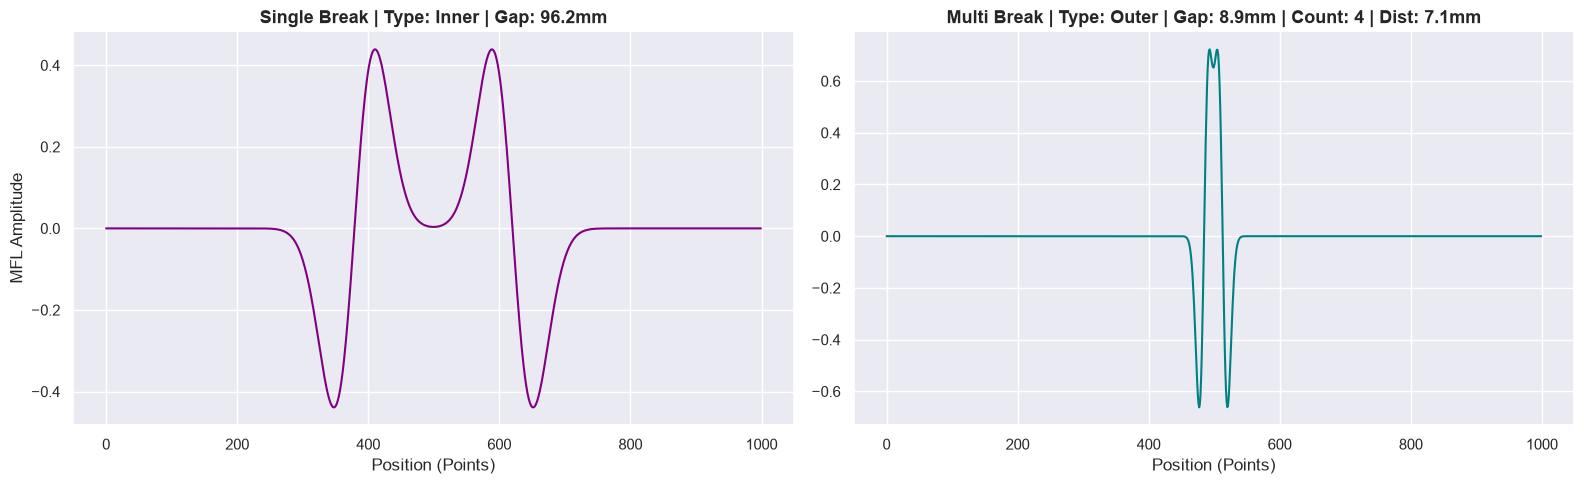

In [7]:
# Load Datasets
single_ds = np.load(os.path.join(SAVE_DIR, "single_dataset.npz"))
multi_ds = np.load(os.path.join(SAVE_DIR, "multi_dataset.npz"))

fault_names = {0: "King", 1: "Inner", 2: "Outer"}
idx_s = np.random.randint(0, len(single_ds['X']))
idx_m = np.random.randint(0, len(multi_ds['X']))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot Single Break Sample
axes[0].plot(single_ds['X'][idx_s], color='purple', linewidth=1.5)
f_type_s = fault_names[single_ds['y_class'][idx_s]]
axes[0].set_title(f"Single Break | Type: {f_type_s} | Gap: {single_ds['y_gap'][idx_s]:.1f}mm", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Position (Points)")
axes[0].set_ylabel("MFL Amplitude")

# Plot Multi Break Sample
axes[1].plot(multi_ds['X'][idx_m], color='teal', linewidth=1.5)
f_type_m = fault_names[multi_ds['y_class'][idx_m]]
axes[1].set_title(f"Multi Break | Type: {f_type_m} | Gap: {multi_ds['y_gap'][idx_m]:.1f}mm | Count: {multi_ds['y_break_count'][idx_m]} | Dist: {multi_ds['y_distance'][idx_m]:.1f}mm", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Position (Points)")

plt.tight_layout()
plt.show()